In [33]:
import pandas as pd
import numpy as np



In [34]:
data=pd.read_csv("D:\\Downloads\\ccf_offline_stage1_train.csv",encoding='utf-8')
print("前五行\n",data.head())
print("数据形状\n",data.shape)
print(data.info())
#Merchant_id商家 ID，Coupon_id优惠券 IDNaN = 没有领券（对照组，自然消费）；有值 = 领到券（实验组）
#Date_received领券日期，Date消费日期，浮点数格式；**NaN = 领券之后没有核销、没有到店消费**
#data

前五行
    User_id  Merchant_id  Coupon_id Discount_rate  Distance  Date_received  \
0  1439408         2632        NaN           NaN       0.0            NaN   
1  1439408         4663    11002.0        150:20       1.0     20160528.0   
2  1439408         2632     8591.0          20:1       0.0     20160217.0   
3  1439408         2632     1078.0          20:1       0.0     20160319.0   
4  1439408         2632     8591.0          20:1       0.0     20160613.0   

         Date  
0  20160217.0  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
数据形状
 (1754884, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754884 entries, 0 to 1754883
Data columns (total 7 columns):
 #   Column         Dtype  
---  ------         -----  
 0   User_id        int64  
 1   Merchant_id    int64  
 2   Coupon_id      float64
 3   Discount_rate  object 
 4   Distance       float64
 5   Date_received  float64
 6   Date           float64
dtypes: float64(4), int64(2), object(1)
memory usage:

In [35]:
print("缺失值：\n",data.isnull().sum())

缺失值：
 User_id               0
Merchant_id           0
Coupon_id        701602
Discount_rate    701602
Distance         106003
Date_received    701602
Date             977900
dtype: int64


In [36]:
print("缺失占比：\n",data.isnull().sum()/len(data))

缺失占比：
 User_id          0.000000
Merchant_id      0.000000
Coupon_id        0.399800
Discount_rate    0.399800
Distance         0.060405
Date_received    0.399800
Date             0.557245
dtype: float64


In [37]:
print("重复行数：\n",data.duplicated().sum())

重复行数：
 37893


In [38]:
print("去重前：\n",data.shape)
data=data.drop_duplicates()
print("去重后：\n",data.shape)

去重前：
 (1754884, 7)
去重后：
 (1716991, 7)


In [39]:
data['is_treat']=data['Coupon_id'].notna() #领券用户
data['is_buy']=data['Date'].notna() #产生消费用户
print(data.head())

   User_id  Merchant_id  Coupon_id Discount_rate  Distance  Date_received  \
0  1439408         2632        NaN           NaN       0.0            NaN   
1  1439408         4663    11002.0        150:20       1.0     20160528.0   
2  1439408         2632     8591.0          20:1       0.0     20160217.0   
3  1439408         2632     1078.0          20:1       0.0     20160319.0   
4  1439408         2632     8591.0          20:1       0.0     20160613.0   

         Date  is_treat  is_buy  
0  20160217.0     False    True  
1         NaN      True   False  
2         NaN      True   False  
3         NaN      True   False  
4         NaN      True   False  


In [40]:
def parse_discount(s):
    if pd.isna(s):
        return np.nan,np.nan
    s=str(s)
    if ":" not in s:
        return np.nan,np.nan
    thresh,reduce_amt=s.split(":")
    return int(thresh),int(reduce_amt)
data[['coupon_threshold','coupon_reduce_amt']]=data['Discount_rate'].apply(
    lambda x: pd.Series(parse_discount(x)))


In [41]:
def convert_date(x):
    if pd.isna(x):
        return pd.NaT
    return pd.to_datetime(str(int(x)),format="%Y%m%d")
data['date_receives_dt']=data['Date_received'].apply(convert_date)
data['date_consume_dt']=data['Date'].apply(convert_date)
print(data.head())

   User_id  Merchant_id  Coupon_id Discount_rate  Distance  Date_received  \
0  1439408         2632        NaN           NaN       0.0            NaN   
1  1439408         4663    11002.0        150:20       1.0     20160528.0   
2  1439408         2632     8591.0          20:1       0.0     20160217.0   
3  1439408         2632     1078.0          20:1       0.0     20160319.0   
4  1439408         2632     8591.0          20:1       0.0     20160613.0   

         Date  is_treat  is_buy  coupon_threshold  coupon_reduce_amt  \
0  20160217.0     False    True               NaN                NaN   
1         NaN      True   False             150.0               20.0   
2         NaN      True   False              20.0                1.0   
3         NaN      True   False              20.0                1.0   
4         NaN      True   False              20.0                1.0   

  date_receives_dt date_consume_dt  
0              NaT      2016-02-17  
1       2016-05-28            

In [42]:
#实验组：领券人群   cvr转化率
treat_data=data[data['is_treat']==True]
treat_buy=treat_data['is_buy'].sum()
treat_total=len(treat_data)
cvr_treat=treat_buy/treat_total   #等价于cvr_treat = treat_df["is_buy"].mean()
#对照组：无券自然消费人群
ctrl_data=data[data['is_treat']==False]
ctrl_buy=ctrl_data['is_buy'].sum()
ctrl_total=len(ctrl_data)
cvr_ctrl=ctrl_buy/ctrl_total
# 增量转化率
uplift=cvr_treat-cvr_ctrl
print(f"实验组成交数：{treat_buy},实验组总数：{treat_total}，转化率 cvr_treat：{cvr_treat:.4f}")
print(f"对照组成交数：{ctrl_buy}，对照组总数：{ctrl_total}，转化率 cvr_ctrl：{cvr_ctrl:.4f}")
print(f"增量转化率 uplift：{uplift:.4f}")

实验组成交数：73064,实验组总数：1015389，转化率 cvr_treat：0.0720
对照组成交数：701602，对照组总数：701602，转化率 cvr_ctrl：1.0000
增量转化率 uplift：-0.9280


## Uplift增量转化率
$$Uplift=CVR_{treat}-CVR_{ctrl}$$
$CVR_{treat}$：领券转化率；$CVR_{ctrl}$：自然转化率
作用：剔除自然转化，得到优惠券真实新增转化

In [43]:
max_consume_date=data['date_consume_dt'].max()

# 新增：标记是否用券消费（领券了，并且消费了 = 券被核销）
data['coupon_used'] = (data['is_treat'] & data['is_buy']).astype(int)

user_agg=data.groupby("User_id").agg(
    buy_cnt=("is_buy","sum"),
    coupon_cnt = ("is_treat", "sum"),
    coupon_use_cnt = ("coupon_used", "sum"),  # 用券消费次数
    total_reduce = ("coupon_reduce_amt", "sum"),
    last_buy_date = ("date_consume_dt", "max")
).reset_index()

In [44]:
# R：距离最近一次消费的天数
user_agg['never_buy']=user_agg['last_buy_date'].isna().astype(int)
user_agg["R"]=(max_consume_date-user_agg["last_buy_date"]).dt.days
#user_agg["R"]=user_agg["R"].fillna(999)

In [45]:
# 真正的券核销率 = 用券消费次数 ÷ 领券次数（范围0~1）
user_agg["true_redemption_rate"]=np.where(
    user_agg["coupon_cnt"]>0,
    user_agg["coupon_use_cnt"]/user_agg["coupon_cnt"],
    0
)

In [46]:
user_agg_valid = user_agg[user_agg["never_buy"] == 0].copy()   #这个用户有消费记录
feat_cols=["R", "buy_cnt", "total_reduce", "true_redemption_rate"]
print(user_agg_valid[feat_cols])

            R  buy_cnt  total_reduce  true_redemption_rate
7        13.0       14          30.0              0.000000
10      123.0        1          25.0              0.500000
11       25.0        1           0.0              0.000000
12      119.0        1           5.0              0.000000
16       16.0        1           2.0              0.000000
...       ...      ...           ...                   ...
539428  160.0        1           1.0              0.000000
539429   34.0        7          30.0              0.333333
539430  154.0        1          20.0              0.000000
539431   95.0        3          10.0              1.000000
539435    4.0        4           7.0              0.000000

[218095 rows x 4 columns]


In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [48]:
x=user_agg_valid[feat_cols].copy()
print(x)

            R  buy_cnt  total_reduce  true_redemption_rate
7        13.0       14          30.0              0.000000
10      123.0        1          25.0              0.500000
11       25.0        1           0.0              0.000000
12      119.0        1           5.0              0.000000
16       16.0        1           2.0              0.000000
...       ...      ...           ...                   ...
539428  160.0        1           1.0              0.000000
539429   34.0        7          30.0              0.333333
539430  154.0        1          20.0              0.000000
539431   95.0        3          10.0              1.000000
539435    4.0        4           7.0              0.000000

[218095 rows x 4 columns]


In [49]:
#标准化
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

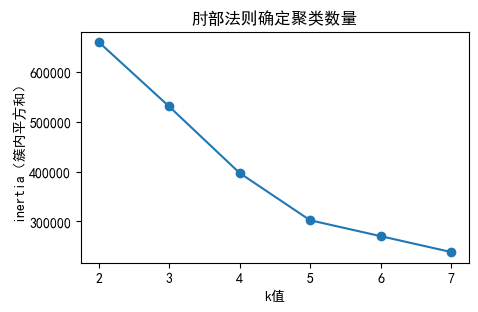

In [50]:
# 肘部法则：确定最佳k值
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

inertia = []
k_range = range(2, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    km.fit(x_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(5,3))
plt.plot(k_range, inertia, marker="o")
plt.xlabel("k值")
plt.ylabel("inertia（簇内平方和）")
plt.title("肘部法则确定聚类数量")
plt.show()

In [51]:
#Kmeans聚类，分4类（贴合我们项目4类人群：自然转化、高潜力增量、低价值、流失）
kmeans=KMeans(n_clusters=4,random_state=42,n_init="auto")
user_agg_valid["cluster"]=kmeans.fit_predict(x_scaled)
cluster_summary = user_agg_valid.groupby("cluster")[feat_cols].mean()
print("各聚类人群特征均值：\n",cluster_summary)
print("每条用户打上簇号：\n",user_agg_valid[["User_id","cluster"]+feat_cols].head())


各聚类人群特征均值：
                   R    buy_cnt  total_reduce  true_redemption_rate
cluster                                                           
0         26.670259  13.916611     73.277796              0.164357
1         35.151029   2.810772     12.844123              0.019698
2         45.163019   4.746023     12.059476              0.785256
3        122.883921   1.412428     16.714246              0.023571
每条用户打上簇号：
     User_id  cluster      R  buy_cnt  total_reduce  true_redemption_rate
7       165        0   13.0       14          30.0                   0.0
10      184        3  123.0        1          25.0                   0.5
11      209        1   25.0        1           0.0                   0.0
12      215        3  119.0        1           5.0                   0.0
16      239        1   16.0        1           2.0                   0.0


In [65]:
cluster_map={
    0: "自然转化用户（不发券也买，少补贴）",
    1: "低价值用户（控制发券）",
    2: "增量高潜力用户（重点发券，ROI最高）",
    3: "流失待召回用户（少量召回券）"
}
user_agg_valid["user_group"]=user_agg_valid["cluster"].map(cluster_map)

In [66]:
print("人群分布：\n",user_agg_valid["user_group"].value_counts())

人群分布：
 user_group
低价值用户（控制发券）            114481
流失待召回用户（少量召回券）          61441
增量高潜力用户（重点发券，ROI最高）     24077
自然转化用户（不发券也买，少补贴）       18096
Name: count, dtype: int64


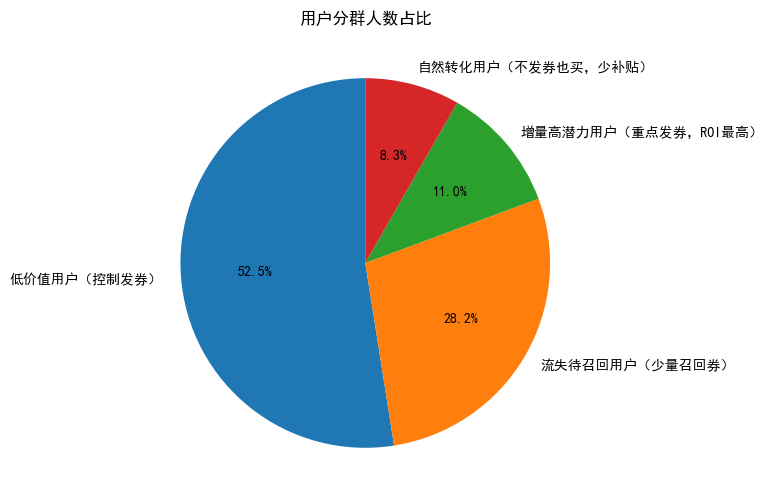

In [67]:
# 人群占比饼图
group_cnt = user_agg_valid["user_group"].value_counts()
plt.figure(figsize=(6,6))
plt.pie(group_cnt, labels=group_cnt.index, autopct="%.1f%%", startangle=90)
plt.title("用户分群人数占比")
plt.show()

In [68]:
# 计算每个人群 RFM 均值
rfm_group = user_agg_valid.groupby("user_group").agg(
    R=("R", "mean"),
    F=("buy_cnt", "mean"),
    M=("total_reduce", "mean")
).reset_index()

print("各人群RFM均值：")
print(rfm_group.round(2))


各人群RFM均值：
            user_group       R      F      M
0          低价值用户（控制发券）   35.15   2.81  12.84
1  增量高潜力用户（重点发券，ROI最高）   45.16   4.75  12.06
2       流失待召回用户（少量召回券）  122.88   1.41  16.71
3    自然转化用户（不发券也买，少补贴）   26.67  13.92  73.28


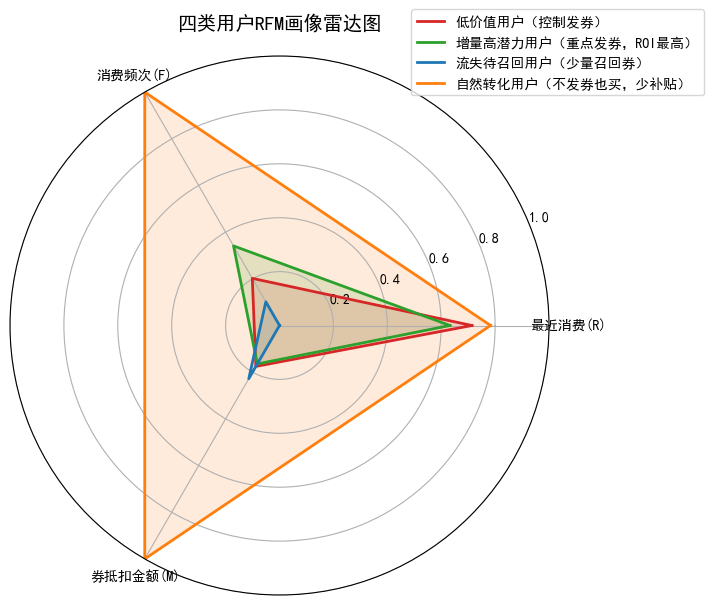

In [69]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 复制上面的rfm_group
df = rfm_group.copy()
labels = ["最近消费(R)", "消费频次(F)", "券抵扣金额(M)"]
# 标准化
df["R_norm"] = 1 - df["R"] / df["R"].max()  # R越小越好，反转
df["F_norm"] = df["F"] / df["F"].max()
df["M_norm"] = df["M"] / df["M"].max()

# 角度
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7,7), subplot_kw=dict(polar=True))
color_list = ["#d62728","#2ca02c","#1f77b4","#ff7f0e"]

for i, row in df.iterrows():
    values = [row["R_norm"], row["F_norm"], row["M_norm"]]
    values += values[:1]
    ax.plot(angles, values, color=color_list[i], linewidth=2, label=row["user_group"])
    ax.fill(angles, values, color=color_list[i], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
ax.set_ylim(0,1)
ax.set_title("四类用户RFM画像雷达图", pad=20, fontsize=14)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.show()


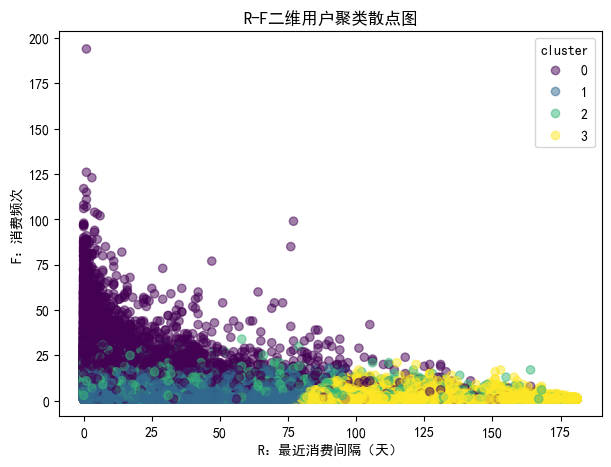

In [70]:
# R-F二维散点图：可视化聚类效果
plt.figure(figsize=(7,5))
scatter = plt.scatter(
    user_agg_valid["R"],
    user_agg_valid["buy_cnt"],
    c=user_agg_valid["cluster"],
    alpha=0.5
)
plt.xlabel("R：最近消费间隔（天）")
plt.ylabel("F：消费频次")
plt.title("R-F二维用户聚类散点图")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.show()

In [71]:
#分人群指标计算：转化率、补贴效率
group_metric=user_agg_valid.groupby("user_group").agg(
    user_cnt = ("User_id", "nunique"),
    total_buy = ("buy_cnt", "sum"),
    total_reduce = ("total_reduce", "sum"),
    total_coupon = ("coupon_cnt", "sum")
).reset_index()

In [72]:
# 人均成交、单券补贴成本、补贴效率：每1元补贴撬动成交单数
group_metric["avg_buy_per_user"] = group_metric["total_buy"] / group_metric["user_cnt"]

In [73]:
# 补贴效率：1块钱补贴能带来多少成交
group_metric["subsidy_efficiency"] = group_metric["total_buy"] / group_metric["total_reduce"]
group_metric = group_metric.sort_values("subsidy_efficiency", ascending=False)
print("分人群营销指标:\n", group_metric.round(4))

分人群营销指标:
             user_group  user_cnt  total_buy  total_reduce  total_coupon  \
1  增量高潜力用户（重点发券，ROI最高）     24077     114270      290356.0         50433   
0          低价值用户（控制发券）    114481     321780     1470408.0        201822   
3    自然转化用户（不发券也买，少补贴）     18096     251835     1326035.0        130637   
2       流失待召回用户（少量召回券）     61441      86781     1026940.0        106274   

   avg_buy_per_user  subsidy_efficiency  
1            4.7460              0.3936  
0            2.8108              0.2188  
3           13.9166              0.1899  
2            1.4124              0.0845  


In [74]:
# 方案1：只给增量高潜力人群发券
target_group = user_agg_valid[user_agg_valid["user_group"] == "增量高潜力用户（重点发券，ROI最高）"]
target_buy = target_group["buy_cnt"].sum()
target_cost = target_group["total_reduce"].sum()
target_efficiency = target_buy / target_cost

In [75]:
# 方案2：全部人群都发券（原来平台旧策略）
all_buy = user_agg_valid["buy_cnt"].sum()
all_cost = user_agg_valid["total_reduce"].sum()
all_efficiency = all_buy / all_cost

In [76]:
print("新旧策略对比[补贴效率：成交单数 / 补贴金额]")
print(f"全量发券（旧策略）补贴效率：{all_efficiency:.4f}")
print(f"仅定向高潜力人群（新策略）补贴效率：{target_efficiency:.4f}")
print("业务结论：停止给自然转化、低价值人群大量发券，把预算倾斜给增量高潜力用户，营销补贴效率显著提升")

新旧策略对比[补贴效率：成交单数 / 补贴金额]
全量发券（旧策略）补贴效率：0.1883
仅定向高潜力人群（新策略）补贴效率：0.3936
业务结论：停止给自然转化、低价值人群大量发券，把预算倾斜给增量高潜力用户，营销补贴效率显著提升


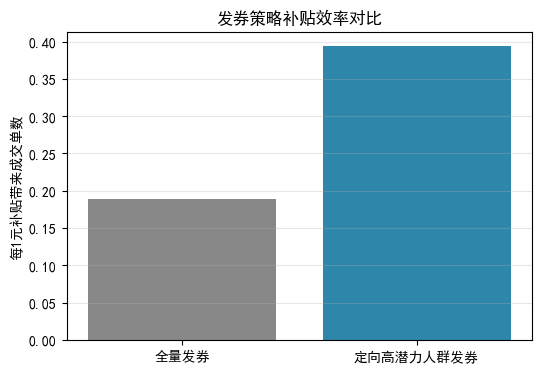

In [77]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

strategies = ["全量发券", "定向高潜力人群发券"]
efficiency = [all_efficiency, target_efficiency]

plt.figure(figsize=(6,4))
plt.bar(strategies, efficiency, color=["#888888","#2E86AB"])
plt.title("发券策略补贴效率对比")
plt.ylabel("每1元补贴带来成交单数")
plt.grid(axis="y",alpha=0.3)
plt.show()
